# This Notebook Is the First Version of The Post Processing of the Simulations. It is the Proof of Concept that the results from Marta's Paper can be Found.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import ast
from collections import defaultdict
import time
import osmnx as ox

# INSERTION CURVE

518256


(array([64407., 16885., 18260., 21687., 19270., 22397., 25636., 18720.,
        17291., 29823., 18304., 24568., 18640., 28198., 15801., 20399.,
        22051., 18746., 20593., 19653., 17415., 15852., 14838.,  8822.]),
 array([7.        , 7.04158102, 7.08316204, 7.12474306, 7.16632407,
        7.20790509, 7.24948611, 7.29106713, 7.33264815, 7.37422917,
        7.41581019, 7.4573912 , 7.49897222, 7.54055324, 7.58213426,
        7.62371528, 7.6652963 , 7.70687731, 7.74845833, 7.79003935,
        7.83162037, 7.87320139, 7.91478241, 7.95636343, 7.99794444]),
 <BarContainer object of 24 artists>)

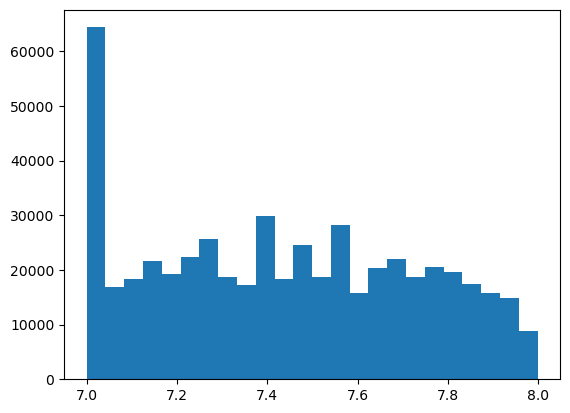

In [ ]:
print(len(dfpeople))
time_dep = dfpeople['time_departure'].to_numpy()/3600
plt.hist(time_dep , bins = 24)

# Phase Transition Analysis

In [ ]:
import os
import sys
sys.path.append(os.path.join(os.environ["TRAFFIC_DIR"],"scripts"))
import shutil
from Directories import *
def CopyCartoGraphy(SourceFile,CityName):
    """
        @params SourceFile: File to copy
        @params DestDir: Directory where to copy the file
        @description : Copy the cartography file in the directory of the simulation
    """
    # Input
    SourceDir = os.path.join(BERKELEY_DIR,CityName)
    SourceFileComplete = os.path.join(SourceDir,SourceFile)
    # Output

    if os.path.exists(SourceFileComplete):
        print(f"Copying {SourceFileComplete} to {NEW_FULL_NETWORK_DIR}")
        shutil.copy(SourceFileComplete,NEW_FULL_NETWORK_DIR)
    else:
        raise Exception(f"CopyCartoGraphy: Cannot copy {SourceFileComplete} : It does not exist")
CopyCartoGraphy('edges.csv',"BOS")

Copying /home/alberto/LPSim/LivingCity/berkeley_2018/BOS/edges.csv to /home/alberto/LPSim/LivingCity/berkeley_2018/new_full_network


# PLOT POPULATION IN CItieS

In [ ]:
import contextily as ctx
import geopandas as gpd
import os
import matplotlib.pyplot as plt
from GeoJsonFunctions import *

g = 0.02
Cities = ['BOS','LAX','SFO','RIO','LIS']
for City in Cities:
    BaseDir = "/home/alberto/LPSim/traffic_phase_transition/data/carto"
    GridDir = os.path.join(BaseDir,f"{City}/grid/{g}")
    GridFile = os.path.join(GridDir,"grid.geojson")
    GeoJsonNodes,GeoJsonEdges,GetGeoJsonBool = GetGeopandas(os.path.join(BaseDir,City,f"{City}_new_tertiary_simplified.graphml"))
    Grid = gpd.read_file(GridFile)
    fig, ax = plt.subplots(1,1, figsize=(17,10))
    if City == "LAX":
        from shapely.geometry import box
        minx, miny, maxx, maxy = -118.951721, 33.65004, -117.646374, 34.823301
        bbox = box(minx, miny, maxx, maxy)

        # Filter the geometries within the bounding box
        Grid = Grid[Grid.geometry.within(bbox)]
        GeoJsonEdges = GeoJsonEdges[GeoJsonEdges.geometry.within(bbox)]
    GeoJsonEdges.plot(ax=ax, alpha = 0.1,color='black', edgecolor='black')
    Grid.plot(column = "population",cmap='viridis',ax=ax, alpha = 0.9,legend=True)
#    ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)
#    plt.savefig(os.path.join(GridDir,"Population.png"),dpi=200)
    plt.show()


# UPLOAD

In [ ]:
import polars as pl
import pandas as pd
from GeoJsonFunctions import *
from PolarsFunctions import *
import json
dtypes = {"p":pl.Int64,
            "init_intersection":pl.Int64,
            "end_intersection":pl.Int64,
            "time_departure":pl.Float64,
            "num_steps":pl.Int64,
            "co":pl.Float32,
            "gas":pl.Float32,
            "distance":pl.Float32,
            "a":pl.Float32,
            "b":pl.Float32,
            "T":pl.Float32,"avg_v(mph)":pl.Float32,
            "active":pl.Int32,
            "last_time_simulated":pl.Int64,
            "path_length_cpu":pl.Int64,
            "path_length_gpu":pl.Int64}
UCI = 0.216
R = 225
#DfPeople = pl.read_parquet("/home/alberto/LPSim/LivingCity/berkeley_2018/BOS/Output/R_220_UCI_0.216_0_people7to24.parquet")
#DfRoute = pl.read_parquet("/home/alberto/LPSim/LivingCity/berkeley_2018/BOS/Output/R_220_UCI_0.216_0_route7to24.parquet")
DfRoute = pl.read_parquet(f"/home/alberto/LPSim/LivingCity/berkeley_2018/BOS/Output/{UCI}/R_{R}_UCI_{UCI}_0_route7to24.parquet")
DfPeople = pl.read_parquet(f"/home/alberto/LPSim/LivingCity/berkeley_2018/BOS/Output/{UCI}/R_{R}_UCI_{UCI}_0_people7to24.parquet")
#DfEdgesCuda = pl.read_csv("/home/alberto/LPSim/0_allPathsInEdgesCUDAFormat7to24.csv")
GeoJsonNodes,GeoJsonEdges,GetGeoJsonBool = GetGeopandas("/home/alberto/LPSim/traffic_phase_transition/data/carto/BOS/BOS_new_tertiary_simplified.graphml")
GeoJsonEdges = CleanGeojson(GeoJsonEdges)
Edges = pl.read_csv('/home/alberto/LPSim/LivingCity/berkeley_2018/new_full_network/edges.csv')
Nodes = pl.read_csv('/home/alberto/LPSim/LivingCity/berkeley_2018/new_full_network/nodes.csv')
#Edges = pl.read_csv("/home/alberto/LPSim/traffic_phase_transition/data/carto/BOS/edges.csv")
#Nodes = pl.read_csv("/home/alberto/LPSim/traffic_phase_transition/data/carto/BOS/nodes.csv")
#DfRoute = DfRoute.join(DfPeople, on="p", how="left")
#DfRoute = DfRoute.with_columns((pl.col("avg_v(mph)")*1.6).alias("avg_v(km/h)"))
#DfRoute = DfRoute.drop(["distance_right","a","b","T","gas","co","path_length_cpu","path_length_gpu","avg_v(mph)"]) # "init_intersection","end_intersection"
#DfRoute = DfRoute.filter(pl.col("num_steps") != 0)    
#DfRoute.with_columns(pl.when(not isinstance(pl.col("avg_v(km/h)"),pl.Float64)).then(pl.col("distance")/(pl.col("last_time_simulated")- pl.col("time_departure"))*3.6).alias("avg_v(km/h)"))
import osmnx as ox
ox.load_graphml("/home/alberto/LPSim/traffic_phase_transition/data/carto/BOS/BOS_new_tertiary_simplified.graphml")

In [ ]:
df = pl.DataFrame(GeoJsonEdges[["capacity","uv"]])
df = df.with_columns([
    pl.col("capacity").cast(pl.Int64),
    pl.col("uv").cast(pl.Int64)
])

In [ ]:
Edges = Edges.join(df, left_on = "uniqueid",right_on = "uv", how = "inner")
Edges

uniqueid,u,v,length,speed_mph,lanes,osmid_u,osmid_v,capacity
i64,i64,i64,f64,i64,i64,i64,i64,i64
0,0,9,51.8,35,1,61816807,61819222,2800
1,0,3,55.4,25,1,61816807,61817409,0
2,0,6,2223.4,35,1,61816807,61818775,2800
3,1,10,1116.2,35,1,61817002,61819564,2800
4,1,9,30.0,35,1,61817002,61819222,2800
…,…,…,…,…,…,…,…,…
54946,23464,23463,15.6,20,1,10281222833,10281222831,0
54947,23465,23463,105.5,20,1,10281222839,10281222831,0
54948,23466,23186,16.9,25,1,10844948681,72474574,2800


# TRANSFORM ROUTES IN DF ROUTES

In [ ]:
t_start_control_group = 7*3600
t_end_control_group = 8*3600
DfRouteControlGroup = FilterDfPeopleControlGroup(t_start_control_group,t_end_control_group,DfRoute,"time_departure","last_time_simulated")
def ComputeGamma(DfRouteControlGroup):
    """
        @param DfRouteControlGroup: DataFrame with the routes of the people in the network
        @return Gamma: Gamma of the Traffic simulation considering just the people of the control group.
    """
    Lexe = DfRouteControlGroup.select(pl.col("length").sum().alias("Lexe"))
    Z = DfRouteControlGroup.select((pl.col("capacity")*pl.col("length")).sum().alias("Z"))
    return (Lexe["Lexe"]/Z["Z"])[0]

Gamma = ComputeGamma(DfRouteControlGroup)
    

In [ ]:
IntTimeArray = np.linspace(0,3600*24,96,dtype = int)
for t in range(len(IntTimeArray)):
    DfRoadsFluxes = DfRoute.with_columns(
        pl.lit(0).alias(f"flux_{t}")
    )
    DfRoadsFluxes = DfRoadsFluxes.with_columns(
        pl.lit(0).alias(f"speed_kmh_{t}")
    )

for t in range(len(IntTimeArray)):
    print(t)
    ConditionUsersInRoad = (pl.col("time_departure") <= IntTimeArray[t]) & (pl.col("time_leaving_road") >= IntTimeArray[t])
    Df2Join = DfRoute.filter(ConditionUsersInRoad).group_by("route").agg([
        (pl.col("avg_v(km/h)")).mean().alias(f"speed_kmh_{t}"),
        pl.col("p").count().alias(f"flux_{t}")
    ])
    if Df2Join.is_empty(): 
        pass
    else:
        DfRoadsFluxes = DfRoadsFluxes.join(Df2Join, on="route", how="left")
DfRoadsFluxes
EdgesWithFluxesAndSpeed = Edges.join(DfRoadsFluxes, left_on='uniqueid', right_on='route', how='left')    
EdgesWithFluxesAndSpeed = EdgesWithFluxesAndSpeed.unique(subset=["u","v"], keep='first')
EdgesWithFluxesAndSpeed = DropColumnsDfIfThere(EdgesWithFluxesAndSpeed,["osmid_u","osmid_v","p","distance","init_intersection","end_intersection","time_departure","last_time_simulated","distance_km","avg_v(m/s)","time_leaving_road","length_km","avg_v(km/h)","length_right","u_right","v_right","capacity_right"])

In [ ]:
GeoJsonEdges

,key,lanes,length,geometry,uv,maxspeed_int,maxspeed_kmh,capacity
uniqueid,,,,,,,,
0,0,2,51.822,"LINESTRING (-70.84463 41.99556, -70.84420 41.9...",0,35,56.3269,2800
1,0,0,55.445,"LINESTRING (-70.84463 41.99556, -70.84459 41.9...",1,0,56.3269,0
2,0,2,2223.414,"LINESTRING (-70.84463 41.99556, -70.84484 41.9...",2,35,56.3269,2800
3,0,2,1116.195,"LINESTRING (-70.84393 41.99608, -70.84384 41.9...",3,35,56.3269,2800
4,0,2,30.030,"LINESTRING (-70.84393 41.99608, -70.84404 41.9...",4,35,56.3269,2800
...,...,...,...,...,...,...,...,...
54946,0,0,15.563,"LINESTRING (-71.44625 42.76344, -71.44629 42.7...",54946,0,56.3269,0
54947,0,0,105.494,"LINESTRING (-71.44541 42.76401, -71.44539 42.7...",54947,0,56.3269,0
54948,0,2,16.852,"LINESTRING (-71.42494 42.56780, -71.42486 42.5...",54948,0,56.3269,2800


# Havlin Percolation Analysis

In [ ]:
import os
from DateTime_ import *
import networkx as nx
import subprocess
from Percolation import *
## PERCOLATION 
PlotDir = '/home/alberto/LPSim/LivingCity/berkeley_2018/BOS/Output/Plots'
MinutesTimeArray = np.array([int(t/60) for t in IntTimeArray])
t_datetime = ConvertVectorMinutesToDatetime(MinutesTimeArray,0,"2024-08-15")
t_hours = CastVectorDateTime2Hours(t_datetime)
q0 = 0.25
q1 = 0.5
q2 = 0.9
for t in range(len(MinutesTimeArray)):
    SinglePlotPercolation(GeoJsonEdges,EdgesWithFluxesAndSpeed,t,t_hours,UCI,R,q0,q1,q2,PlotDir)
EdgesWithFluxesAndSpeed = ComputePercolationColumns(EdgesWithFluxesAndSpeed,IntTimeArray,q0,q1,q2)
G = ConvertGeoJsonEdges2NetworkX(EdgesWithFluxesAndSpeed, IntTimeArray) 
Components = ComputeConnectedComponentsGonT(G, IntTimeArray)
PlotNumberLinksTwoBiggestConnectedComponents(Components, t_hours,UCI,R,PlotDir)   

# DIRECTED PERCOLATION

In [ ]:
EdgesWithFluxesAndSpeed


uniqueid,u,v,length,speed_mph,lanes,capacity,time_entering_road,flux_95,speed_kmh_95,speed_kmh_28,flux_28,speed_kmh_29,flux_29,speed_kmh_30,flux_30,speed_kmh_31,flux_31,speed_kmh_32,flux_32,speed_kmh_33,flux_33,speed_kmh_34,flux_34,speed_kmh_35,flux_35,speed_kmh_36,flux_36,speed_kmh_37,flux_37,speed_kmh_38,flux_38,speed_kmh_39,flux_39,speed_kmh_40,flux_40,speed_kmh_41,…,flux_77,speed_kmh_78,flux_78,speed_kmh_79,flux_79,speed_kmh_80,flux_80,speed_kmh_81,flux_81,speed_kmh_82,flux_82,speed_kmh_83,flux_83,speed_kmh_84,flux_84,speed_kmh_85,flux_85,speed_kmh_86,flux_86,speed_kmh_87,flux_87,speed_kmh_88,flux_88,speed_kmh_89,flux_89,speed_kmh_90,flux_90,speed_kmh_91,flux_91,speed_kmh_92,flux_92,speed_kmh_93,flux_93,speed_kmh_94,flux_94,speed_kmh_95_right,flux_95_right
i64,i64,i64,f64,i64,i64,i64,f64,i32,i32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,…,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32
23072,9631,8765,2293.3,30,1,2800,25690.962919,0,0,44.14217,20,42.853045,5,45.208315,8,45.07064,4,44.718945,4,44.773986,5,44.705464,8,44.542816,3,46.737482,2,43.960877,2,47.800855,2,46.144916,3,45.680579,6,49.03448,…,4,45.249589,7,44.194867,6,42.247528,1,44.59755,1,42.729741,2,43.998435,3,45.023997,3,42.950634,2,44.971157,4,44.793093,1,42.892612,1,45.03959,2,46.22019,3,null,null,46.344672,1,43.950252,1,null,null,null,null
8636,3540,4910,304.9,25,1,4200,25234.536561,0,0,41.74594,52,40.447181,23,38.553726,34,38.763991,29,42.30277,27,44.888571,20,42.294905,19,42.541777,16,42.427055,7,42.930303,10,48.67937,8,46.964106,7,41.170837,7,42.205823,…,11,44.533615,13,40.39263,11,41.905996,16,43.312961,11,43.82315,13,44.071839,12,43.87645,16,39.342649,9,39.958487,15,38.388279,5,42.167746,9,42.323487,9,45.093365,7,39.580504,4,38.833801,4,38.588446,4,35.543853,4,null,null
15235,6337,6382,480.4,30,2,4800,26255.242376,0,0,42.076691,24,41.960563,11,39.523847,14,40.49096,17,29.567009,8,33.752155,9,27.723057,7,28.599821,8,25.980204,7,32.116712,7,30.283947,4,29.589026,4,33.733898,5,32.523173,…,10,43.425122,5,44.300191,1,44.578152,5,42.272925,7,43.769967,5,41.081618,3,41.308002,7,35.817924,3,37.123712,4,35.841361,7,37.892722,7,33.746537,3,25.741937,2,29.65342,2,29.769209,2,28.110893,2,31.483063,4,null,null
25744,10692,12227,61.5,50,2,3600,26314.16959,0,0,54.03975,771,53.673357,664,54.570102,584,54.849403,390,61.047378,320,65.267173,190,67.154614,139,67.257183,112,68.780056,127,69.258588,72,70.036802,61,67.61355,41,66.283812,47,64.116416,…,44,68.9127,56,75.437955,25,66.628337,60,67.679941,41,68.088559,38,69.664848,21,69.985091,49,70.298591,28,68.754141,26,67.820168,23,74.301495,23,71.63574,21,68.260931,23,72.991095,13,74.598039,12,75.951371,6,77.198861,8,null,null
22834,9538,9492,36.3,25,1,4200,25310.861819,0,0,39.181545,44,39.795142,21,39.064955,30,35.36721,22,34.255014,19,30.350651,14,23.611236,11,25.260294,14,27.039447,15,20.526657,11,24.232494,12,18.282169,9,22.009139,10,20.538405,…,4,45.631189,8,43.050259,1,51.969664,11,56.694623,5,46.636225,10,47.024633,6,58.741042,10,57.960168,5,59.203784,8,57.717637,5,57.271453,9,57.910692,3,49.326353,5,52.133092,4,57.10468,3,56.828472,2,65.842881,5,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
415,155,138,149.5,35,1,3200,26767.641524,0,0,53.127169,214,55.231743,83,52.427447,68,53.252133,45,55.157981,55,59.047574,40,57.191707,36,59.341206,36,58.823994,47,59.864993,21,58.790522,21,58.682439,19,59.797164,27,59.166965,…,39,57.341444,29,56.979424,38,54.960847,45,56.640247,40,55.37347,39,57.770765,36,59.006506,36,57.435466,35,57.791301,36,57.748828,28,56.169125,26,58.719662,21,60.20714,22,61.757308,21,61.29244,17,59.198638,12,67.638383,11,null,null
22596,9445,9239,127.8,30,1,4800,28733.135281,0,0,39.366705,123,39.01803,72,37.077752,86,34.558373,62,35.044

In [ ]:
DfRoute

p,distance,init_intersection,end_intersection,time_departure,last_time_simulated,route,avg_v(km/h),u,v,length,capacity,length_km,distance_km,avg_v(m/s),time_leaving_road,time_entering_road
i64,f64,i64,i64,f64,i64,i64,f64,i64,i64,f64,i64,f64,f64,f64,f64,f64
104557,45374.4,75265895,67496490,25200.0,28488,50968,49.68,21679,20905,1097.1,2400,1.0971,45.3744,13.8,25279.5,25200.0
104557,45374.4,75265895,67496490,25200.0,28488,49086,49.68,20905,20918,492.6,2400,0.4926,45.3744,13.8,25315.195652,25279.5
104557,45374.4,75265895,67496490,25200.0,28488,49118,49.68,20918,20855,1672.6,2400,1.6726,45.3744,13.8,25436.398551,25315.195652
104557,45374.4,75265895,67496490,25200.0,28488,48978,49.68,20855,21862,49.9,2400,0.0499,45.3744,13.8,25440.014493,25436.398551
104557,45374.4,75265895,67496490,25200.0,28488,51365,49.68,21862,22110,12.1,1600,0.0121,45.3744,13.8,25440.891304,25440.014493
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
7060577,368.6,65985583,65933034,86382.9,86400,9304,77.6,3826,320,368.6,2800,0.3686,0.3686,21.555556,86400.0,86382.9
6964475,415.4,70787161,70726135,86388.8,86400,40097,133.521429,17100,17090,46.6,2800,0.0466,0.4154,37.089286,86390.056428,86388.8
6964475,415.4,70787161,70726135,86388.8,86400,40072,133.521429,17090,17878,135.9,2800,0.1359,0.4154,37.089286,86393.720558,86390.056428


# This script defines the EdgesWithPeopleTrappedInTime that contains a column list_p_{t} of people trapped in edge e. NOTE: Useful to count the transition rates. 

In [ ]:
import numpy as np
Every2MinutesArray = np.arange(IntTimeArray[0],IntTimeArray[-1],20)
for col in DfRoute.columns:
    if "right" in col:
        DfRoute = DfRoute.drop(col)
First = True
def compute_intersection(row):
    return list(set(row[0]).intersection(set(row[1])))

# Apply the custom function to compute the intersection for each row


for t in range(len(Every2MinutesArray) - 1):
    print(t)
    # Users in interval IntTimeArray[t] and IntTimeArray[t+1]
    in_roads_at_t = DfRoute.filter(
        (pl.col("time_entering_road") <= Every2MinutesArray[t]) &
        (pl.col("time_leaving_road") >= Every2MinutesArray[t+1]))
    in_roads_at_t_plus_1 = DfRoute.filter(
        (pl.col("time_entering_road") <= Every2MinutesArray[t+1]) &
        (pl.col("time_leaving_road") >= Every2MinutesArray[t+2]))
    
#    grouped = in_roads_at_t[["route","p"]].group_by(pl.col("route")).agg(
#        pl.struct(pl.col("p"),pl.col("route")).alias(f"list_p_r_{t}"))
    # Group Users by route at t
    grouped_t = in_roads_at_t.group_by("route").agg(
        pl.col("p").alias(f"list_p_{t}")
    )
    # Group users at time t + 1
    grouped_t_plus_1 = in_roads_at_t_plus_1.group_by("route").agg(
        pl.col("p").alias(f"list_p_{t+1}")
    )
    # Compute the length of the list of users in the route
    grouped_t = grouped_t.with_columns(
        pl.col(f"list_p_{t}").list.len().alias(f"G_e_{t}")
    )
    if grouped_t.is_empty():
        continue

    else:
        grouped_t_explode = grouped_t.explode(f"list_p_{t}")
        grouped_t_plus_one_explode = grouped_t_plus_1.explode(f"list_p_{t+1}")
        # Collect the user that are in one but not in 2 (they are those that exit the road network)
        Exited = pl.sql(f"SELECT * FROM grouped_t_explode WHERE list_p_{t} NOT IN grouped_t_plus_1_explode.list_p_{t+1}").collect()
        print(Exited)

        Join_group_t_t_plus_1 = grouped_t.join(grouped_t_plus_1, on="route", how="cross")
        print("AFTER JOIN\n",Join_group_t_t_plus_1)
        # Compute the intersection between e and e' for all e'
        Join_group_t_t_plus_1 = Join_group_t_t_plus_1.select(pl.struct([f"list_p_{t}",f"list_p_{t+1}"]).map_batches(compute_intersection).alias(f'intersection_{t}'))
        
        print("after interection:`n",Join_group_t_t_plus_1)
        Join_group_t_t_plus_1 = Join_group_t_t_plus_1.with_columns(
            pl.col(f'intersection_{t}').list.len().alias(f'G_e_{t+1}'))
        # Trapped function is the percolation probability
        
        # NOTE: Need to drop the columns that are bigger then 1 since these are artifacts due to the fact that I consider time intervals that are too large.
        
        ColsInEdgesWithFluxesAndSpeed = ["uniqueid","u","v","capacity"]
        if len(grouped_t) > 0:
            if First == True:

                # Join the aggregated list back to the original DataFrame
                EdgesWithPeopleTrappedInTime = EdgesWithFluxesAndSpeed[ColsInEdgesWithFluxesAndSpeed].join(grouped_t, left_on="uniqueid",right_on="route", how="full")
                First = False
            else:
                EdgesWithPeopleTrappedInTime = EdgesWithPeopleTrappedInTime.join(grouped_t, on="route", how="full")

# LAUNCH ANALYSIS UCI R

In [ ]:
from TrajectoryAnalysis import *
#from TrajectoryAnalysisWithoutPlots import *
from OutputStats import *
from GenerateConfiguraiton import *
import warnings
import multiprocessing
import json
warnings.filterwarnings("ignore")
BaseConfig = os.path.join(os.environ["TRAFFIC_DIR"],"config")
list_cities = os.listdir(os.path.join(os.environ["TRAFFIC_DIR"],'data','carto'))
list_cities = ["RIO"]#["BOS","SFO","RIO"]
ListPeopleFile = []
ListRoutesFile = []
complete_path_info_simulations_df = os.path.join(TRAFFIC_DIR,"info_simulations.csv")

def MainMultiprocessing(City):
    """
        @City: str
        Description:
            - For each city, load the configuration file
            - For each UCI, load the output file
            - For each R, load the output file
            - Compute the average unload curve
            - Compute the average volume traffic
            - Compute the average speed
    """

#        City2Config,Rs,UCIs = InitConfigPolycentrismAnalysis(City)  
    Df_Info_Simulations = pl.read_csv(complete_path_info_simulations_df)
    Rs = Df_Info_Simulations.filter(pl.col("city") == City)["R"].unique().to_numpy()
    UCIs = Df_Info_Simulations.filter(pl.col("city") == City)["UCI"].unique().to_numpy()
    UCIs = [0.633,0.683,0.693]
#    print("Rs\n",Rs)
#    print("UCIs\n",UCIs)
    Df_City2Config = Df_Info_Simulations.filter(pl.col("city") == City)    
    # 10) NOTE: Analyze the Output
    PCTA = Polycentrism2TrafficAnalyzer(Df_City2Config,Rs,UCIs)  
    PCTA.CompleteAnalysis()

if False:
    with multiprocessing.Pool(3) as p:
        p.map(MainMultiprocessing, list_cities)
#City = list_cities[0]
for City in list_cities:
    MainMultiprocessing(City)

# Routine Averaging over UCI of Interval:

In [2]:
# Parameters
from PlotsPercolationAggregated import *
from dictionaries_percolation_analysis import *
from pipeline_InfoTraffic import *
from pipeline_aggregation import *
from pipeline_relevant_choose_compute_df_unload import *
from Beta import *
from postprocessing_simulation_aggregated import *
# Input
t_start_hour = 7
t_end_control_group = 8*3600
start_bin_time_considered_in_beta_fit = 39
# --- Completed Simulations
BaseConfig = os.path.join(os.environ["TRAFFIC_DIR"],"config")                           # Info about simulations
list_cities = os.listdir(os.path.join(os.environ["TRAFFIC_DIR"],'data','carto'))        # Info about cities
list_cities = ["RIO","SFO"]#["SFO","RIO"]#["BOS","SFO","RIO"]
ListPeopleFile = []
ListRoutesFile = []
TRAFFIC_DIR = os.environ["TRAFFIC_DIR"]                                                 # NOTE: base dir project
complete_path_info_simulations_df = os.path.join(TRAFFIC_DIR,"info_simulations.csv")
# Available simulations
Df_Info_Simulations = pl.read_csv(complete_path_info_simulations_df)
# The cases are thought as:
# 1) Aggregated_UCIs: -> UCI interval -> each DfUnload corresponds to the average of the DfUnload of all the UCIs in the UCI interval
# 2) Single_UCI: -> UCI interval -> each DfUnload corresponds to the DfUnload of the UCI in the UCI interval
cases = ["Single_UCI"]                                                                  #["Aggregated_UCIs","Single_UCI"]
case_ = "Single_UCI"                                                                    # Choose the case to analyze
delta_RC_plot_before = 120
delta_RC_plot_after = 80
delta_RC_plot_1 = 200

# NOTE: FIT Params
init_time_hour_cut_for_fit = 1
minimum_time_with_people = 10
max_time_for_fit = 6

# UCI
UCI_intervals = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]  # UCI intervals to consider

colors = [
    # Original 20 colors
    '#1f77b4',  # Blue
    '#ff7f0e',  # Orange
    '#2ca02c',  # Green
    '#d62728',  # Red
    '#9467bd',  # Purple
    '#8c564b',  # Brown
    '#e377c2',  # Pink
    '#7f7f7f',  # Gray
    '#bcbd22',  # Olive
    '#17becf',  # Cyan
    '#aec7e8',  # Light blue
    '#ffbb78',  # Light orange
    '#98df8a',  # Light green
    '#ff9896',  # Light red
    '#c5b0d5',  # Light purple
    '#c49c94',  # Light brown
    '#f7b6d2',  # Light pink
    '#c7c7c7',  # Light gray
    '#dbdb8d',  # Light olive
    '#9edae5',  # Light cyan
    
    # Darker versions of the first 10
    '#0d5a8c',  # Dark blue
    '#d35400',  # Dark orange
    '#1e6b1e',  # Dark green
    '#b21e1e',  # Dark red
    '#6d4394',  # Dark purple
    '#6d4331',  # Dark brown
    '#c2549c',  # Dark pink
    '#4d4d4d',  # Dark gray
    '#9a9c18',  # Dark olive
    '#0e8c98',  # Dark cyan
    
    # Additional colors
    '#8a2be2',  # Blueviolet
    '#a52a2a',  # Brown
    '#deb887',  # Burlywood
    '#5f9ea0',  # Cadetblue
    '#7fff00',  # Chartreuse
    '#d2691e',  # Chocolate
    '#dc143c',  # Crimson
    '#00ffff',  # Cyan/Aqua
    '#00008b',  # Dark blue
    '#008b8b',  # Dark cyan
    
    # Lighter versions of additional colors
    '#c299ff',  # Light blueviolet
    '#d48a8a',  # Light brown
    '#ffe4c4',  # Light burlywood
    '#a3d1d3',  # Light cadetblue
    '#c0ff84',  # Light chartreuse
    '#e8ad7d',  # Light chocolate
    '#f08080',  # Light crimson
    '#e0ffff',  # Light cyan
    '#7171c6',  # Light dark blue
    '#66cccc'   # Light dark cyan
]

UCI_interval_2_color = get_UCI_interval_2_colormap(UCI_intervals)

# Compute City_UCI_2_var_of_interest

In [ ]:


City_2_UCI_2_R2InfoTraffic, City_2_UCI_2_CriticalParams, City_2_UCI_2_R2NtNtFit, City_2_UCI_2_Time2FitBeta, City_2_UCI_2_ErrorBeta_in_Time,City_2_UCI_interval_2_UCISimulation, City_2_UCI_interval_2_Rs_available_to_all_UCIs,t_vect = compute_City_2_UCI_2_var_interest(case_,
                                                                                                                                                                                                                                                                Df_Info_Simulations,
                                                                                                                                                                                                                                                                list_cities,
                                                                                                                                                                                                                                                                t_start_hour,
                                                                                                                                                                                                                                                                t_end_control_group,
                                                                                                                                                                                                                                                                start_bin_time_considered_in_beta_fit,
                                                                                                                                                                                                                                                                init_time_hour_cut_for_fit = init_time_hour_cut_for_fit,
                                                                                                                                                                                                                                                                minimum_time_with_people = minimum_time_with_people,
                                                                                                                                                                                                                                                                max_time_for_fit = max_time_for_fit)




In [4]:
City_2_UCI_2_Rc = defaultdict(dict)
for City in City_2_UCI_2_CriticalParams.keys():
    City_2_UCI_2_Rc[City] = defaultdict(list)
    UCIs = []
    Rcs = []
    Betas = []
    t_inftys = []
    Gammas_c = []
    Taus_c = []
    for UCI in City_2_UCI_2_CriticalParams[City].keys():
        beta = City_2_UCI_2_CriticalParams[City][UCI]["beta"]
        if City == "SFO":
            condition = UCI >= 0.4 and UCI <= 0.9 and UCI != 0.561 and beta > 0
        elif City=="RIO":
            condition = beta > 0
        if condition:
            Rc = City_2_UCI_2_CriticalParams[City][UCI]["Rc"]
            UCIs.append(UCI)
            Rcs.append(Rc)
            Betas.append(City_2_UCI_2_CriticalParams[City][UCI]["beta"])
            t_inftys.append(City_2_UCI_2_CriticalParams[City][UCI]["t_infty"])
            Gammas_c.append(City_2_UCI_2_CriticalParams[City][UCI]["Gammac"])
            Taus_c.append(City_2_UCI_2_CriticalParams[City][UCI]["Tauc"])
    City_2_UCI_2_Rc[City]["UCI"] = UCIs
    City_2_UCI_2_Rc[City]["Rc"] = Rcs
    City_2_UCI_2_Rc[City]["Beta"] = Betas
    City_2_UCI_2_Rc[City]["t_infty"] = t_inftys
    City_2_UCI_2_Rc[City]["Gammac"] = Gammas_c
    City_2_UCI_2_Rc[City]["Tauc"] = Taus_c


# Plot Cities Separately

In [ ]:
for City in list_cities:
    dir_base_analyzed_simulations = os.path.join("/data_2/alberto",City,"Output")                                               # NOTE: base dir for input
    dir_output_aggregated = os.path.join(dir_base_analyzed_simulations,case_)                                            # NOTE: base dir for output
    dir_output_aggregated_all_cities = os.path.join("/data_2/alberto",case_)                                             # NOTE: base dir for output when we aggregate over all cities    
    print(f"xxxxxxxxxxxxxxxxxxxxxxxxxxxxx {City} Plotting xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx")
    color_idx = 0
    fig_nr,ax_nr = plt.subplots(1,1,figsize = (10,10))
    ax_inset = create_inset_plot(fig_nr,ax_nr)
    fig_gamma_tau,ax_gamma_tau = plt.subplots(1,1,figsize = (10,10))
    fig_tau_alpha,ax_tau_alpha = plt.subplots(1,1,figsize = (10,10))
    fig_alpha_beta,ax_alpha_beta = plt.subplots(1,1,figsize = (10,10))
    UCI_2_Time2FitBeta = City_2_UCI_2_Time2FitBeta[City]
    UCI_2_R2NtNtFit = City_2_UCI_2_R2NtNtFit[City]
    UCI_2_CriticalParams = City_2_UCI_2_CriticalParams[City]
    UCI_2_R2InfoTraffic = City_2_UCI_2_R2InfoTraffic[City]
    UCI_interval_2_UCISimulation = City_2_UCI_interval_2_UCISimulation[City]
    UCI_interval_2_Rs_available_to_all_UCIs = City_2_UCI_interval_2_Rs_available_to_all_UCIs[City]
    for UCI_interval, UCIs in UCI_interval_2_UCISimulation.items():
        # NOTE: Clarify whether the phase transition is found or not
        for UCI in UCIs:
            if City == "SFO":
                condition = UCI > 0.4 and UCI != 0.564 and UCI < 0.9 
            elif City == "RIO":
                condition = True
            if condition:
                Gammas, Taus, Rs_plot_tau = get_vecs_gammas_taus_from_R2Infotraffic(UCI_2_R2InfoTraffic[UCI])
                print(f"{City}: get gammas,taus from UCI: {UCI}")
                Rc,Tauc,alpha,Gammac,is_phase_transition_found = get_Rc_Tc_Gc_is_pht_from_CritPar(UCI_2_CriticalParams,UCI)            
                # NOTE: plot_gamma_tau needed variables                
                UCI_plots = UCI
                idx_color = get_UCI_interval_from_UCI(UCI,UCI_intervals)
                color =  colors[idx_color]
                
                Rs_interval = UCI_interval_2_Rs_available_to_all_UCIs[UCI_interval] if UCI_interval in UCI_interval_2_Rs_available_to_all_UCIs else []
                if is_phase_transition_found:
                    Time2FitBeta = UCI_2_Time2FitBeta[UCI]
                    R2NtNtFit = UCI_2_R2NtNtFit[UCI]
                    CriticalParams = UCI_2_CriticalParams[UCI]
                    t_star = CriticalParams["t_infty"]      
                    beta = CriticalParams["beta"]
                    IndexRc = [i for i, R in enumerate(Rs_interval) if int(R) == int(Rc)][0]
                    if beta > 0:
                        # NOTE: plot n(R)
                        int_t_star = CriticalParams["int_t_infty"]
                        nRs,RsOverRc, epsilons = get_nR_R2Rc_epsilons_from_R2NtNtFit(R2NtNtFit, int_t_star,Rc)
                        epsilon_fit = Time2FitBeta[int_t_star]["epsilon"]
                        nR_fit = Time2FitBeta[int_t_star]["n(R,epsilon)_fit"]
                        nR_region_fit = Time2FitBeta[int_t_star]["n(R,epsilon)"]
                        print(f"{City}: Phase Trans - Plotting n(R) UCI: {UCI}") 
                        print("nR: ",nRs)
                        print("nR_fit: ",nR_fit)
                        ax_nr =     single_plot_nr(RsOverRc,
                                                    nRs,
                                                    epsilons,
                                                    City,
                                                    ax_nr,
                                                    color,
                                                    beta_ = None,
                                                    UCI = UCI,                                                # NOTE: UCI -> UCI of the city
                                                    )
                        ax_inset = single_plot_inset_nR(ax_inset,
                                        nR_fit,
                                        epsilon_fit,
                                        nR_region_fit,
                                        City,  
                                        color)    
                        ax_gamma_tau = single_plot_gamma_tau(Taus,
                                    Gammas,
                                    Gammac,
                                    Tauc,
                                    IndexRc,
                                    City,
                                    UCI,
                                    color,                                # NOTE: color -> color of the plot
                                    ax_gamma_tau)   
                        ax_tau_alpha = single_plot_R_tau_alpha(Rs_plot_tau,
                                                                Taus,
                                                                alpha,
                                                                Tauc,
                                                                Rc,
                                                                City,
                                                                ax_tau_alpha,
                                                                color,
                                                                UCI=UCI)
                    else:
                        print(f"{City}: UCI: {UCI}, Error in plotting n(R), gamma, tau, alpha")
                    color_idx += 1                                                              # NOTE: Update the color idx
    finalize_inset(ax_nr, ax_inset)
    # NOTE: Plot alpha betas in terms of UCI after having plot everything for R
    ax_alpha_beta = single_plot_alpha_beta_UCI(UCI_2_CriticalParams,
                               City,
                               ax_alpha_beta,
                               colors,
                               UCI_intervals)                           
    fig_nr.savefig(f"{dir_output_aggregated}/{City}_nr.png")
    fig_gamma_tau.savefig(f"{dir_output_aggregated}/{City}_gamma_tau.png")
    fig_tau_alpha.savefig(f"{dir_output_aggregated}/{City}_tau_alpha.png")
    fig_alpha_beta.savefig(f"{dir_output_aggregated}/{City}_alpha_beta.png")
    plt.close(fig_nr)
    plt.close(fig_gamma_tau)
    plt.close(fig_tau_alpha)
    plt.close(fig_alpha_beta)
    



# Plot UCI-Rc

In [ ]:
CITY2COLOR = {"BOS":"red",
              "LIS":"blue",
              "LAX":"green",
              "SFO":"orange",
              "RIO":"purple"
              }
CITY2MARKER = {"BOS":"o",
               "LIS":"s",
               "LAX":"^",
               "SFO":"D",
               "RIO":"P"}

fig, ax = plt.subplots(1,1,figsize=(10,6))
for City in City_2_UCI_2_Rc.keys():
    ax.scatter(City_2_UCI_2_Rc[City]["UCI"],City_2_UCI_2_Rc[City]["Rc"],marker=CITY2MARKER[City],color=CITY2COLOR[City],label=City)
    np.polyfit(City_2_UCI_2_Rc[City]["UCI"], City_2_UCI_2_Rc[City]["Rc"], 1)
    ax.plot(City_2_UCI_2_Rc[City]["UCI"], np.polyval(np.polyfit(City_2_UCI_2_Rc[City]["UCI"], City_2_UCI_2_Rc[City]["Rc"], 1), City_2_UCI_2_Rc[City]["UCI"]), color=CITY2COLOR[City], linestyle='--')
ax.set_xlabel("UCI")
ax.set_ylabel("Rc")
ax.legend()
plt.savefig(os.path.join("/data_2/alberto","Rc_vs_UCI.png"),dpi=200)
plt.close(fig)

fig, ax = plt.subplots(1,1,figsize=(10,6))
for City in City_2_UCI_2_Rc.keys():
    ax.scatter(City_2_UCI_2_Rc[City]["UCI"],City_2_UCI_2_Rc[City]["Beta"],marker=CITY2MARKER[City],color=CITY2COLOR[City],label=City)
    np.polyfit(City_2_UCI_2_Rc[City]["UCI"], City_2_UCI_2_Rc[City]["Beta"], 1)
    ax.plot(City_2_UCI_2_Rc[City]["UCI"], np.polyval(np.polyfit(City_2_UCI_2_Rc[City]["UCI"], City_2_UCI_2_Rc[City]["Beta"], 1), City_2_UCI_2_Rc[City]["UCI"]), color=CITY2COLOR[City], linestyle='--')
ax.set_xlabel("UCI")
ax.set_ylabel(r"$\beta$")
ax.legend()
plt.savefig(os.path.join("/data_2/alberto","Beta_vs_UCI.png"),dpi=200)
plt.close(fig)

fig, ax = plt.subplots(1,1,figsize=(10,6))
for City in City_2_UCI_2_Rc.keys():
    ax.scatter(City_2_UCI_2_Rc[City]["UCI"],City_2_UCI_2_Rc[City]["t_infty"],marker=CITY2MARKER[City],color=CITY2COLOR[City],label=City)
ax.set_xlabel("UCI")
ax.set_ylabel(r"$t_{\infty}$")
ax.legend()
plt.savefig(os.path.join("/data_2/alberto","t_infty_vs_UCI.png"),dpi=200)
plt.close(fig)

fig, ax = plt.subplots(1,1,figsize=(10,6))
for City in City_2_UCI_2_Rc.keys():
    ax.scatter(City_2_UCI_2_Rc[City]["UCI"],City_2_UCI_2_Rc[City]["Gammac"],marker=CITY2MARKER[City],color=CITY2COLOR[City],label=City)
    np.polyfit(City_2_UCI_2_Rc[City]["UCI"], City_2_UCI_2_Rc[City]["Gammac"], 1)
    ax.plot(City_2_UCI_2_Rc[City]["UCI"], np.polyval(np.polyfit(City_2_UCI_2_Rc[City]["UCI"], City_2_UCI_2_Rc[City]["Gammac"], 1), City_2_UCI_2_Rc[City]["UCI"]), color=CITY2COLOR[City], linestyle='--')
ax.set_xlabel("UCI")
ax.set_ylabel(r"$\Gamma_c$")
ax.legend()
plt.savefig(os.path.join("/data_2/alberto","Gammac_vs_UCI.png"),dpi=200)
plt.close(fig)

fig, ax = plt.subplots(1,1,figsize=(10,6))
for City in City_2_UCI_2_Rc.keys():
    ax.scatter(City_2_UCI_2_Rc[City]["UCI"],City_2_UCI_2_Rc[City]["Tauc"],marker=CITY2MARKER[City],color=CITY2COLOR[City],label=City)
    np.polyfit(City_2_UCI_2_Rc[City]["UCI"], City_2_UCI_2_Rc[City]["Tauc"], 1)
    ax.plot(City_2_UCI_2_Rc[City]["UCI"], np.polyval(np.polyfit(City_2_UCI_2_Rc[City]["UCI"], City_2_UCI_2_Rc[City]["Tauc"], 1), City_2_UCI_2_Rc[City]["UCI"]), color=CITY2COLOR[City], linestyle='--')
ax.set_xlabel("UCI")
ax.set_ylabel(r"$\tau_c$")
ax.legend()
plt.savefig(os.path.join("/data_2/alberto","Tauc_vs_UCI.png"),dpi=200)
plt.close(fig)




# Single City, single UCI

In [ ]:
for City in list_cities:
    dir_base_analyzed_simulations = os.path.join("/data_2/alberto",City,"Output")                                               # NOTE: base dir for input
    dir_output_aggregated = os.path.join(dir_base_analyzed_simulations,case_)                                            # NOTE: base dir for output
    dir_output_aggregated_all_cities = os.path.join("/data_2/alberto",case_)                                             # NOTE: base dir for output when we aggregate over all cities    
    print(f"xxxxxxxxxxxxxxxxxxxxxxxxxxxxx {City} Plotting xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx")
    color_idx = 0
    UCI_2_Time2FitBeta = City_2_UCI_2_Time2FitBeta[City]
    UCI_2_R2NtNtFit = City_2_UCI_2_R2NtNtFit[City]
    UCI_2_CriticalParams = City_2_UCI_2_CriticalParams[City]
    UCI_2_R2InfoTraffic = City_2_UCI_2_R2InfoTraffic[City]
    UCI_interval_2_UCISimulation = City_2_UCI_interval_2_UCISimulation[City]
    UCI_interval_2_Rs_available_to_all_UCIs = City_2_UCI_interval_2_Rs_available_to_all_UCIs[City]
    UCI_2_ErrorBeta_in_Time = City_2_UCI_2_ErrorBeta_in_Time[City]
    for UCI_interval, UCIs in UCI_interval_2_UCISimulation.items():
        # NOTE: Clarify whether the phase transition is found or not
        for UCI in UCIs:
            if City == "SFO":
                condition = UCI > 0.4 and UCI != 0.564
            elif City == "RIO":
                condition = True
            if condition:
                Gammas, Taus, Rs_plot_tau = get_vecs_gammas_taus_from_R2Infotraffic(UCI_2_R2InfoTraffic[UCI])
                print(f"{City}: get gammas,taus from UCI: {UCI}")
                Rc,Tauc,alpha,Gammac,is_phase_transition_found = get_Rc_Tc_Gc_is_pht_from_CritPar(UCI_2_CriticalParams,UCI)            
                # NOTE: plot_gamma_tau needed variables                
                UCI_plots = UCI
#                color = UCI_interval_2_color[UCI_interval] if UCI_interval in UCI_interval_2_color else colors[color_idx]
                idx_color = get_UCI_interval_from_UCI(UCI,UCI_intervals)
                color =  colors[idx_color]

                Rs_interval = UCI_interval_2_Rs_available_to_all_UCIs[UCI_interval] if UCI_interval in UCI_interval_2_Rs_available_to_all_UCIs else []
                if is_phase_transition_found:
                    fig_nt_scaled,ax_nt_scaled = plt.subplots(1,1,figsize = (10,10))
                    fig_nt,ax_nt = plt.subplots(1,1,figsize = (10,10))
                    UCI_plots = UCI
                    Time2FitBeta = UCI_2_Time2FitBeta[UCI]
                    R2NtNtFit = UCI_2_R2NtNtFit[UCI]
                    CriticalParams = UCI_2_CriticalParams[UCI]
                    t_star = CriticalParams["t_infty"]

                count_labels_above = 0
                count_labels_below = 0
                for R in Rs_interval:
                    print(f"---------------------------- {City} - {UCI} - R = {R} ----------------------------")
                    # NOTE: Plot being aware of whether the phase transtion occured
                    if is_phase_transition_found:
                        # NOTE: Initialize features that are of interest for time evolution
                        vec_nt = np.array(UCI_2_R2NtNtFit[UCI][R]["n"])               # NOTE: vector of fraction of people in the road in time
                        vec_nt_fit = np.array(UCI_2_R2NtNtFit[UCI][R]["n_fit"])       # NOTE: vector of fit for fraction of people in the road in time -> TimeHourArray
                        vec_t = np.array(t_vect)
                        is_alpha = int(R) == int(Rc)                                           # NOTE: is_alpha -> boolean if the alpha needs to be plotted
                        if City == "RIO":
                            delta_RC_plot_before = 400
                            delta_RC_plot_after = 20
                            delta_RC_plot_1 = 320
                        else:
                            pass
                        is_label_below = (int(R) > int(Rc) - delta_RC_plot_before) and int(R) < int(Rc)
                        is_label_above0 = int(R) > int(Rc) + delta_RC_plot_after
                        is_label_above1 = int(R) < int(Rc) + delta_RC_plot_1
                        is_label_above = is_label_above0 and is_label_above1
                        if is_label_below:
                            count_labels_below += 1
                        if is_label_above:
                            count_labels_above += 1
                        if count_labels_above > 3:
                            is_label_above = False
                        if count_labels_below > 3:
                            is_label_below = False
                        is_label = is_label_below or is_label_above
                        print(f"{City}: R {R} is_label_below: {is_label_below}, is_label_above0: {is_label_above0}, is_label_above1: {is_label_above1}, is_label_above: {is_label_above}, -> is_label: {is_label}")
                        # NOTE: needed -> single_plot_nt_alpha
                        epsilon = np.abs(int(R)**2 - int(Rc**2))/int(Rc)**2                                              # NOTE: epsilon -> value of the epsilon parameter
                        # NOTE: plot_gamma_tau needed variables                
                        IndexRc = [i for i, R in enumerate(Rs_interval) if int(R) == int(Rc)][0]
                        print(f"{City}: Phase Trans - Plotting nt R: {R}, UCI: {UCI}")
                        ax_nt = single_plot_nt_aggregated_single_city(vec_nt,                  # NOTE: vector of  fraction of people in the road in time
                                                                    vec_t,                    # NOTE: vector of time -> TimeHourArray
                                                                    is_alpha,                 # NOTE: is_alpha -> boolean if the alpha needs to be plotted
                                                                    alpha,                    # NOTE: alpha -> power-law for the phase transition
                                                                    R,                        # NOTE: R -> value of the R parameter
                                                                    t_star,                   # NOTE: t_star -> time of best fit of beta 
                                                                    vec_nt_fit,               # NOTE: vector of fit for fraction of people in the road in time -> TimeHourArray
                                                                    is_label,                 # NOTE: is_label -> boolean if the label needs to be plotted
                                                                    City,                     # NOTE: city -> name of the city
                                                                    ax_nt,                    # NOTE: ax1 -> axis of the plot
                                                                    is_savgol = False,        # NOTE: is_savgol -> boolean if the savgol filter needs to be applied
                        )
                        # NOTE: Condition on the existence of epsilon
                        print(f"{City}: Phase Trans - Plotting nt^alpha R: {R}, UCI: {UCI}")
                        ax_nt_scaled = single_plot_nt_alpha_aggregated_single_city(vec_nt,                   # NOTE: vector of  fraction of people in the road in time
                                                                vec_t,                          # NOTE: vector of time -> TimeHourArray
                                                                epsilon,                        # NOTE: epsilon -> value of the epsilon parameter
                                                                is_alpha,                       # NOTE: is_alpha -> boolean if the alpha needs to be plotted
                                                                alpha,                          # NOTE: alpha -> power-law for the phase transition
                                                                R,                              # NOTE: R -> value of the R parameter
                                                                vec_nt_fit,                     # NOTE: vector of fit for fraction of people in the road in time -> TimeHourArray
                                                                is_label,                       # NOTE: is_label -> boolean if the label needs to be plotted
                                                                City,                           # NOTE: city -> name of the city
                                                                ax_nt_scaled,                   # NOTE: ax1 -> axis of the plot
                                                                init_time_hour_cut_for_fit = init_time_hour_cut_for_fit, # NOTE: init_time_hour_cut_for_fit -> initial time for the fit  
                                                                max_time_for_fit = max_time_for_fit,           # NOTE: max_time_for_fit -> maximum time for the fit                                                    
                                                                is_savgol = False,              # NOTE: is_savgol -> boolean if the savgol filter needs to be applied
                                                                savgol_window = 3,              # NOTE: savgol_window -> window for the savgol filter
                                                                City_2_Marker = CITY2MARKER,    # NOTE: City_2_Marker -> dictionary of the city and the marker
                                                                City_2_Color = CITY2COLOR,      # NOTE: City_2_Color -> dictionary of the city and the color
                        )
#                print(f"{City}: Phase Trans - Plotting Error Beta in Time R: {R}, UCI: {UCI}")  
#                print(f"{City}: UCI: {UCI}, t_star: {t_star}")
#                print(f"{City}: UCI: {UCI}, beta_fit_time: {UCI_2_ErrorBeta_in_Time[UCI]['beta_fit_time']}")
#                print(f"{City}: UCI: {UCI}, error_beta_fit_time: {UCI_2_ErrorBeta_in_Time[UCI]['error_beta_fit_time']}")
#                print(f"{City}: UCI: {UCI}, time_fit: {UCI_2_ErrorBeta_in_Time[UCI]['time_fit']}") 
                if is_phase_transition_found:
                    fig_nt.savefig(f"{dir_output_aggregated}/nt_{City}_{UCI}.png")
                    fig_nt_scaled.savefig(f"{dir_output_aggregated}/scaled_nt_{City}_{UCI}.png")
                    plt.close(fig_nt)
                    plt.close(fig_nt_scaled)
                try:
                    fig_error_beta_in_time,ax_error_beta_in_time = plt.subplots(1,1,figsize = (10,10))
                    beta_fit_time = [float(beta_exp) for beta_exp in UCI_2_ErrorBeta_in_Time[UCI]["beta_fit_time"]]
                    error_fit_beta = [float(error_beta) for error_beta in UCI_2_ErrorBeta_in_Time[UCI]["error_beta_fit_time"]]
                    time_fit = [t for t in UCI_2_ErrorBeta_in_Time[UCI]["time_fit"]]
                    ax_error_beta_in_time = single_plot_error_associated_to_powerlaw_beta(beta_fit_time,
                                                                                    error_fit_beta,
                                                                                    time_fit,
                                                                                    t_star,
                                                                                    City,
                                                                                    UCI,
                                                                                    ax_error_beta_in_time)
                    fig_error_beta_in_time.savefig(f"{dir_output_aggregated}/error_beta_in_time_{City}_{UCI}.png")
                    plt.close(fig_error_beta_in_time)
                except Exception as e:
                    print(f"{City}: UCI: {UCI}, Error in plotting Error Beta in Time: {e}")
                    ax_error_beta_in_time = None
#                try:
                if is_phase_transition_found:
                    fig_gamma_tau,ax_gamma_tau = plt.subplots(1,1,figsize = (10,10))
                    fig_tau_alpha,ax_tau_alpha = plt.subplots(1,1,figsize = (10,10))
                    fig_nr,ax_nr = plt.subplots(1,1,figsize = (10,10))
                    ax_inset = create_inset_plot(fig_nr,ax_nr,"lower right")                    
                    int_t_star = CriticalParams["int_t_infty"]
                    nRs,RsOverRc, epsilons = get_nR_R2Rc_epsilons_from_R2NtNtFit(R2NtNtFit, int_t_star,Rc)
                    if int_t_star > 0: #NOTE: temporary bug
                        epsilon_fit = Time2FitBeta[int_t_star]["epsilon"]
                        nR_fit = Time2FitBeta[int_t_star]["n(R,epsilon)_fit"]
                        nR_region_fit = Time2FitBeta[int_t_star]["n(R,epsilon)"]    
                        beta = CriticalParams["beta"]
                        print(f"{City}: Phase Trans - Plotting n(R) R: {R}, UCI: {UCI}") 
                        print("nR: ",nRs)
                        print("nR_fit: ",nR_fit)
                        ax_nr =     single_plot_nr(RsOverRc,
                                                nRs,
                                                epsilons,
                                                City,
                                                ax_nr,
                                                color,
                                                beta_ = beta,
                                                UCI = UCI,                                                # NOTE: UCI -> UCI of the city
                                                )
                        ax_inset = single_plot_beta_fit(Time2FitBeta,
                                t_star,
                                int_t_star,
                                t_vect,
                                ax_inset)
                        finalize_inset(ax_nr, ax_inset)
                        fig_nr.savefig(f"{dir_output_aggregated}/nr_{City}_{UCI}.png")
                        plt.close(fig_nr)

                        ax_gamma_tau = single_plot_gamma_tau(Taus,
                                    Gammas,
                                    Gammac,
                                    Tauc,
                                    IndexRc,
                                    City,
                                    UCI,
                                    color,                                # NOTE: color -> color of the plot
                                    ax_gamma_tau)
                        fig_gamma_tau.savefig(f"{dir_output_aggregated}/gamma_tau_{City}_{UCI}.png")
                        plt.close(fig_gamma_tau)
    ##                 
                        ax_tau_alpha = single_plot_R_tau_alpha(Rs_plot_tau,
                                                Taus,
                                                alpha = alpha,
                                                Tauc = Tauc,
                                                Rc = Rc,
                                                City = City,
                                                ax = ax_tau_alpha,
                                                color = color,
                                                UCI=UCI)
                        fig_tau_alpha.savefig(f"{dir_output_aggregated}/tau_alpha_{City}_{UCI}.png")
                        plt.close(fig_tau_alpha)


#                except Exception as e:
#                    print(f"{City}: UCI: {UCI}, Error in plotting n(R), gamma, tau, alpha: {e}")
#                    ax_nr = None
#                    ax_gamma_tau = None
#                    ax_tau_alpha = None
                color_idx += 1                                                              # NOTE: Update the color idx


# All together

In [ ]:
# NOTE: 08/06/2025 -> canceled 0.564 from SFO file

# Write the Latex script with the wanted images

In [ ]:
def generate_phase_transition_latex(City_2_UCI_2_CriticalParams):
    """
    Generate LaTeX figure code for phase transition analysis.
    
    Args:
        City_2_UCI_2_CriticalParams: Dictionary containing critical parameters for each city and UCI
        
    Returns:
        str: Complete LaTeX code for all qualifying figures
    """
    
    def get_city_name(city_code):
        """Convert city code to full name for caption."""
        city_names = {
            "SFO": "San Francisco",
            "RIO": "Rio De Janeiro",
            "BOS": "Boston",
            "LAX": "Los Angeles",
            "LIS": "Lisbon"
        }
        return city_names.get(city_code, city_code)
    
    def generate_single_figure_latex(city, uci, beta):
        """Generate LaTeX code for a single UCI figure."""
        city_lower = city.lower()
        city_name = get_city_name(city)
        
        latex_code = f"""\\begin{{figure}}
    \\centering
    \\begin{{subfigure}}{{0.5\\textwidth}}
        \\includegraphics[width=\\linewidth]{{nt_{city}_{uci}.png}}
        \\caption{{}}
        \\label{{fig:{city_lower}_{uci}_nt}}
    \\end{{subfigure}}%
    \\begin{{subfigure}}{{0.5\\textwidth}}
        \\includegraphics[width=\\linewidth]{{scaled_nt_{city}_{uci}.png}}
        \\caption{{}}
        \\label{{fig:{city_lower}_{uci}_scaled_nt}}
    \\end{{subfigure}}
    
    \\begin{{subfigure}}{{0.5\\textwidth}}
        \\includegraphics[width=\\linewidth]{{nr_{city}_{uci}.png}}
        \\caption{{}}
        \\label{{fig:{city_lower}_{uci}_nr}}
    \\end{{subfigure}}%
    \\begin{{subfigure}}{{0.5\\textwidth}}
        \\includegraphics[width=\\linewidth]{{gamma_tau_{city}_{uci}.png}}
        \\caption{{}}
        \\label{{fig:{city_lower}_{uci}_gamma_tau}}
    \\end{{subfigure}}
    \\caption{{Here are represented the important features about the phase transition in {city_name} for UCI = {uci}.
    In \\ref{{fig:{city_lower}_{uci}_nt}} is represented the number of people trapped in the road network at time t. In \\ref{{fig:{city_lower}_{uci}_scaled_nt}}, the vertical line representing $t_{{\\infty}}$. we see the values $n(t)t^{{\\alpha}}$ over $\\epsilon (t-t_0)$, with $\\epsilon = \\frac{{R^2 - R_c^2}}{{R_c^2}}$ with t up to $t_{{start}} + t_{{end_{{fit}}}}$ In \\ref{{fig:{city_lower}_{uci}_nr}} showing the phase transition requirement. We plot n(R,$t_{{\\infty}}$) with $\\beta = $ {beta:.3f}. In \\ref{{fig:{city_lower}_{uci}_gamma_tau}} we see the linear increase of $\\tau$ compared to $\\Gamma$}}
    \\label{{fig:phase_transition_{city_lower}_{uci}}}
\\end{{figure}}

"""
        return latex_code
    
    # Generate LaTeX for all qualifying figures
    latex_output = ""
    
    for City, UCI_2_CriticalParams in City_2_UCI_2_CriticalParams.items():
        for UCI, CriticalParams in UCI_2_CriticalParams.items():
            beta = CriticalParams["beta"]
            
            # Apply the filtering conditions
            if City == "SFO":
                condition = UCI >= 0.4 and UCI <= 0.9 and UCI != 0.561 and beta > 0
            elif City == "RIO":
                condition = beta > 0
            else:
                condition = beta > 0  # Default condition for other cities
            
            if condition:
                latex_output += generate_single_figure_latex(City, UCI, beta)
    
    return latex_output

# Usage example:
if __name__ == "__main__":
    # Assuming you have your City_2_UCI_2_CriticalParams dictionary
    latex_code = generate_phase_transition_latex(City_2_UCI_2_CriticalParams)
    print(latex_code)
    
    # Or save to file
    with open("phase_transition_figures.tex", "w") as f:
        f.write(latex_code)

In [ ]:
def generate_latex_figures():
    """
    Generate LaTeX figure code for RIO and SFO datasets with multiple subfigures.
    """
    
    # Data for RIO and SFO
    rio_values = [0.027, 0.091, 0.092, 0.099, 0.102, 0.114, 0.125, 0.127, 0.215, 0.241, 0.297, 0.298, 0.315, 0.317, 0.348, 0.349, 0.413, 0.457, 0.458, 0.48, 0.519, 0.543, 0.561, 0.563, 0.581, 0.633, 0.679, 0.683, 0.693, 0.709, 0.779, 0.789, 0.79, 0.82, 0.832, 0.856, 0.88, 0.904, 0.95, 0.979, 0.999]
    sfo_values = [0.002, 0.003, 0.04, 0.044, 0.111, 0.145, 0.15, 0.153, 0.2, 0.259, 0.263, 0.293, 0.345, 0.353, 0.377, 0.389, 0.445, 0.463, 0.468, 0.469, 0.515, 0.537, 0.564, 0.566, 0.595, 0.603, 0.607, 0.611, 0.632, 0.7, 0.703, 0.744, 0.75, 0.818, 0.821, 0.832, 0.841, 0.927, 0.974, 0.989, 0.995]
#    rio_values = [0.027, 0.127, 0.241, 0.315, 0.543, 0.79, 0.82, 0.95]
#    sfo_values = [0.468, 0.515, 0.632, 0.744, 0.821]
    
    # Figure configurations
    figure_configs = [
        {
            'prefix': 'scaled_nt',
            'label_suffix': 'nt_talpha',
            'caption': 'here are represented $n(t)t^{{\\alpha}}$ for the different configurations in {0} \\ref{{fig:DistrPopulation{1}}}'
        },
        {
            'prefix': 'nt',
            'label_suffix': 'nt',
            'caption': 'here are represented fraction of people still in the road network at time t $n_R(t)$ for the different configurations in {0} \\ref{{fig:DistrPopulation{1}}}'
        },
        {
            'prefix': 'gamma_tau',
            'label_suffix': 'gamma_tau',
            'caption': 'here are represented recovery time $\\tau$ with the loading fraction $\\Gamma$ for the different configurations in {0} \\ref{{fig:DistrPopulation{1}}}'
        },
        {
            'prefix': 'nr',
            'label_suffix': 'nr',
            'caption': 'here are represented fraction of people still in the road network at time $t_{{\\infty}}$ $n(R,t_{{\\infty}})$ for the different configurations in {0} \\ref{{fig:DistrPopulation{1}}}'
        }
    ]
    
    def generate_figure(city, values, config):
        """Generate a single figure with multiple subfigures."""
        city_upper = city.upper()
        city_title = "RIO" if city.upper() == "RIO" else "SFO"
        
        # Calculate subfigure width based on number of plots
        num_plots = len(values)
        if num_plots <= 5:
            width = 0.19  # 5 plots per row
        else:
            width = 0.19  # 5 plots per row
        
        latex_code = f"""\\begin{{figure}}
    \\centering"""
        
        # Generate subfigures
        for i, value in enumerate(values):
            if i > 0 and i % 5 == 0:
                latex_code += "\n    \n"  # New line after every 5 subfigures
            
            latex_code += f"""
    \\begin{{subfigure}}{{{width}\\textwidth}}
        \\includegraphics[width=\\linewidth]{{{config['prefix']}_{city_upper}_{value}.png}}
        \\caption{{}}
        \\label{{fig:{city.lower()}_{value}_{config['label_suffix']}}}
    \\end{{subfigure}}"""
            
            if (i + 1) % 5 != 0 and i < len(values) - 1:
                latex_code += "%"
        
        # Add caption and label
        caption_text = config['caption'].format(city_title, city_title)
        latex_code += f"""
    \\caption{{{caption_text}}}
    \\label{{fig:{config['label_suffix']}_{city_upper}_all}}
\\end{{figure}}

"""
        return latex_code
    
    # Generate all figures
    latex_output = ""
    
    # RIO figures
    latex_output += "% RIO Figures\n"
    for config in figure_configs:
        latex_output += generate_figure("RIO", rio_values, config)
    
    # SFO figures  
    latex_output += "% SFO Figures\n"
    for config in figure_configs:
        latex_output += generate_figure("SFO", sfo_values, config)
    
    return latex_output

# Generate and print the LaTeX code
if __name__ == "__main__":
    latex_code = generate_latex_figures()
    print(latex_code)
    


# Plot Unload Curve Example

In [ ]:
import polars as pl
import matplotlib.pyplot as plt
from PolarsFunctions import *
from OutputStats_Functions import *
from DateTimeHandler import *
HOURS_IN_DAY = 24
MINUTES_IN_HOUR = 60
SECONDS_IN_MINUTE = 60
TIMESTAMP_OFFSET = 6*3600
t_start_control_group = 7*3600
t_end_control_group = 8*3600
t_start_plot = 6*3600
DfPeople = pl.read_parquet("/data_2/alberto/BOS/Output/0.168/R_820_UCI_0.168_realization_0_0_people7to24.parquet")
DfRoute = pl.read_parquet("/data_2/alberto/BOS/Output/0.168/R_820_UCI_0.168_realization_0_0_route7to24.parquet")
Edges = pl.read_csv("/home/alberto/LPSim/traffic_phase_transition/data/carto/BOS/edges.csv")

IntTimeArray, HourTimeArray, Interval2NumberPeopleInNet = InitializeTimeVariablesOutputStats(HOURS_IN_DAY,MINUTES_IN_HOUR,SECONDS_IN_MINUTE,TIMESTAMP_OFFSET,delta_t = 10)
Interval2NotCgroupNumberPeopleInNet = Interval2NumberPeopleInNet.copy()  
if len(IntTimeArray) != len(HourTimeArray):
    mask = np.array(IntTimeArray) >= t_start_control_group
    IntTimeArray = IntTimeArray[mask]
keys_Interval2NumberPeopleInNet = list(Interval2NumberPeopleInNet.keys())
DfControlGroup = FilterDfPeopleControlGroup(t_start_control_group,
                                            t_end_control_group,
                                            DfPeople,
                                            "time_departure",
                                            "last_time_simulated")
#                    print(f"{self.city}, {self.R}, {self.UCI}, After filtering 1, DfControlGroup:\n",DfControlGroup.head())
DfControlGroup = EmbdedTrajectoriesInRoadsAndTime(DfRoute,
                                                DfControlGroup,
                                                Edges)

DfNotControlGroup = EmbdedTrajectoriesInRoadsAndTime(DfRoute,
                                                DfPeople,
                                                Edges)



for t in range(len(Interval2NumberPeopleInNet.keys())-1):
    # DataFrame Filtered With People in the Network at time t in the time interval t,t+1
    DfPeopleInNetAtTimet = FilterDfPeopleStilInNet(IntTimeArray[t],
                                                    IntTimeArray[t+1],
                                                    "last_time_simulated",
                                                    DfControlGroup)
    DfNotControlGroupAtTimet = FilterDfPeopleStilInNet(IntTimeArray[t],
                                                    IntTimeArray[t+1],
                                                    "last_time_simulated",
                                                    DfNotControlGroup)
    Interval2NumberPeopleInNet[keys_Interval2NumberPeopleInNet[t]] += len(DfPeopleInNetAtTimet) 
    Interval2NotCgroupNumberPeopleInNet[keys_Interval2NumberPeopleInNet[t]] += len(DfNotControlGroupAtTimet)

data = {
    "Time": list(IntTimeArray[:-1]),
    "Time_Str": list(HourTimeArray[:-1]),
    "NumberPeople": list(Interval2NumberPeopleInNet.values())
}
DfUnload = pl.DataFrame(data)
# Add Time_hours column
DfUnload = DfUnload.with_columns(
    (pl.col("Time") / 3600).alias("Time_hours")
)
DfUnload = DfUnload.filter(pl.col("Time") > t_start_plot)


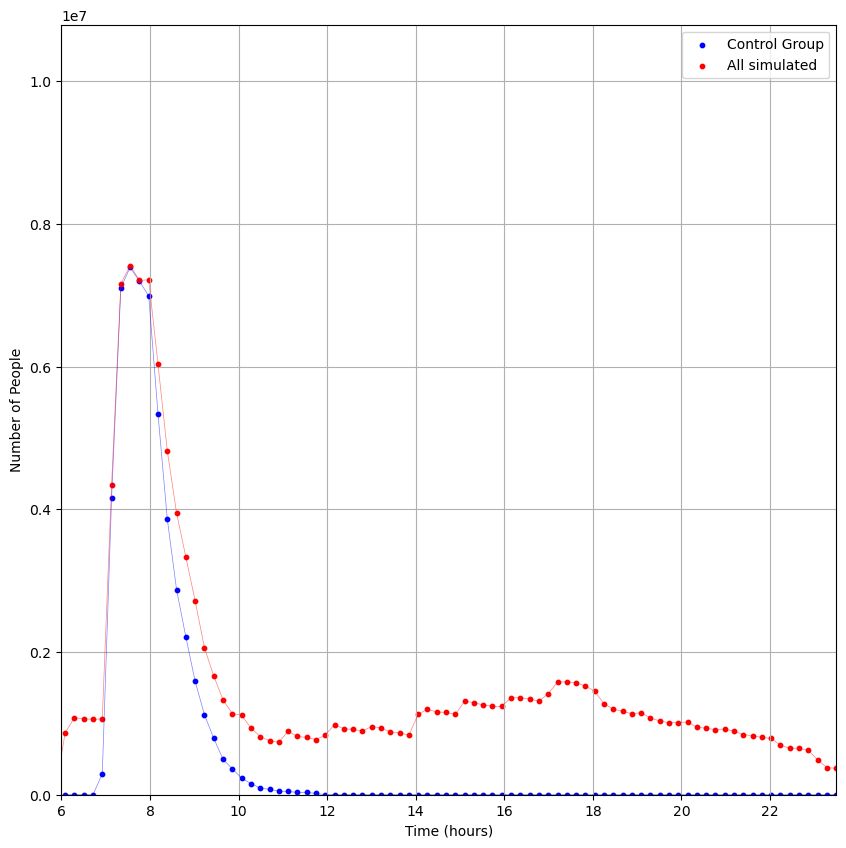

In [25]:
t_start_hour = 7
DfUnload = DfUnload.with_columns((pl.col("Time_hours") - t_start_hour).alias("Time_hours_shifted"))
DfUnload = DfUnload.with_columns((pl.col("NumberPeople") > 0).alias("IsPeople"))
DfUnload = DfUnload.with_columns((pl.col("Time") >= t_end_control_group).alias("IsUnload"))

data_1 = {
    "Time": list(IntTimeArray[:-1]),
    "Time_Str": list(HourTimeArray[:-1]),
    "NumberPeople": list(Interval2NotCgroupNumberPeopleInNet.values())
}
DfUnloadNotCgroup = pl.DataFrame(data_1)
DfUnloadNotCgroup = DfUnloadNotCgroup.with_columns(
    (pl.col("Time") / 3600).alias("Time_hours")
)

DfUnloadNotCgroup = DfUnloadNotCgroup.with_columns((pl.col("Time_hours") - t_start_hour).alias("Time_hours_shifted"))
DfUnloadNotCgroup = DfUnloadNotCgroup.with_columns((pl.col("NumberPeople") > 0).alias("IsPeople"))
DfUnloadNotCgroup = DfUnloadNotCgroup.with_columns((pl.col("Time") >= t_end_control_group).alias("IsUnload"))


fig,ax = plt.subplots(1,1,figsize = (10,10))
ax.scatter(DfUnload["Time_hours"], DfUnload["NumberPeople"], label = "Control Group", color = "blue", s = 10)
ax.plot(DfUnload["Time_hours"], DfUnload["NumberPeople"], color = "blue", linewidth = 0.5, alpha = 0.5)
ax.scatter(DfUnloadNotCgroup["Time_hours"], DfUnloadNotCgroup["NumberPeople"], label = "All simulated", color = "red", s = 10)
ax.plot(DfUnloadNotCgroup["Time_hours"], DfUnloadNotCgroup["NumberPeople"], color = "red", linewidth = 0.5, alpha = 0.5)
ax.set_xlabel("Time (hours)")
ax.set_ylabel("Number of People")
ax.set_xlim(6,23.5)
ax.set_ylim(0, DfUnload["NumberPeople"].max())
ax.legend()
ax.grid(True)
plt.savefig("/home/alberto/LPSim/traffic_phase_transition/data/control_group_and_all_simulated_people.png")

In [ ]:

def shift_time_columns_if_needed(df):
    """
    Check if the first time_departure value is >= 8*3600 (8 hours),
    and if so, shift both time columns by -3600 seconds (1 hour).
    
    Args:
        df: Polars DataFrame containing 'time_departure' and 'last_time_simulated' columns
        
    Returns:
        Polars DataFrame with potentially shifted time columns
    """
    # Get the first element of time_departure
    first_departure = df.select(pl.col("time_departure").first()).item()
    
    # Check if the first time_departure is >= 8 hours (in seconds)
    if first_departure >= 8 * 3600:
        print(f"First departure time is {first_departure/3600:.2f} hours, shifting all times by -1 hour")
        
        # Apply the shift to both columns
        return df.with_columns([
            (pl.col("time_departure") - 3600).alias("time_departure"),
            (pl.col("last_time_simulated") - 3600).alias("last_time_simulated")
        ])
    else:
        print(f"First departure time is {first_departure/3600:.2f} hours, no shift needed")
        return df
df = pl.read_parquet("/data_2/alberto/SFO/Output/0.445/R_40_UCI_0.445_realization_0_0_people7to24.parquet")
df = df.sort("time_departure")
shift_time_columns_if_needed(df)

First departure time is 7.00 hours, no shift needed


p,init_intersection,end_intersection,time_departure,num_steps,co,gas,distance,a,b,T,avg_v(mph),active,last_time_simulated,path_length_cpu,path_length_gpu
i64,i64,i64,f64,i64,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64
0,56031956,56031956,25200.0,0,0.0,0.0,0.0,0.557041,2.90206,0.543303,null,2,25200,0,0
1,56031956,275574461,25200.0,143,37.2803,291.974,2751.9,0.557041,2.90206,0.543303,39.7671,2,25342,9,9
2,56031956,275568678,25200.0,255,80.6289,756.109,6265.4,0.557041,2.90206,0.543303,53.2583,2,25454,8,8
3,56031956,56114011,25200.0,28,9.81617,29.1101,309.0,0.557041,2.90206,0.543303,13.2898,2,25227,1,1
4,56031956,1970942371,25200.0,152,43.0294,317.504,2687.1,0.557041,2.90206,0.543303,36.6258,2,25351,7,7
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
6878949,1082968293,1081556049,86349.3,51,14.9458,58.6899,185.2,0.557041,2.90206,0.543303,19.2708,1,86400,29,4
6852927,3984423298,3984423551,86350.0,51,13.6245,75.0429,532.1,0.557041,2.90206,0.543303,23.8885,1,86400,7,5
6862702,352764033,57816894,86354.4,46,13.0503,60.2612,299.0,0.557041,2.90206,0.543303,20.9106,1,86400,5,1


In [ ]:
import matplotlib.pyplot as plt
import json
import numpy as np
import os
Cities = ["BOS","SFO","RIO"]


def ChooseBesttFromTime2FitBeta(Time2FitBeta):
    """
        @param Time2FitBeta: Dictionary with the time to fit beta for each city
            n(R,epsilon)
            epsilon
        @return beta_star: Best beta, that is the one that minimizes in time the best fit.
        @return t_star: Time in which beta_star is computed.
        @return best_y_fit: Best fit.
        @return epsilon_in_best_fit: Epsilon in the best fit.
        @return beta_star2: Second best beta, that is the one that minimizes in time the second best fit.
        NOTE: we constraint it to be the minimum after some predefinite time.
        @return t_star2: Time in which beta_star2 is computed.
        @return best_y_fit2: Second best fit.
        @return epsilon_in_best_fit2: Epsilon in the second best fit.
        @return errors: Errors in the fit.
        @return error_index: Index of the errors.
        @return betas: List of betas. (for each time interval)
        @return betas: List of errors. (for each time interval)

    """
    MinError = 10**5
    Minerror2 = 10**5
    errors = []
    error_index = []
    betas = []
    print(Time2FitBeta)
    for t in Time2FitBeta.keys():
        log_epsilon = np.log(np.array(Time2FitBeta[t]["epsilon"]))
        log_n_Repsilon = np.log(np.array(Time2FitBeta[t]["n(R,epsilon)"]))
        linear_fit = np.polyfit(log_epsilon,log_n_Repsilon,1)
        beta = linear_fit[0]
        int_t = int(t)
        if not np.isnan(beta): 
            y_fit = np.exp(linear_fit[1])*np.array(Time2FitBeta[t]["epsilon"])**beta
            y = np.array(Time2FitBeta[t]["n(R,epsilon)"])
            error_t = np.sqrt(np.sum((y_fit - y)**2)/len(Time2FitBeta[t]["n(R,epsilon)"]))
            errors.append(error_t)
            error_index.append(int_t/6)
            betas.append(beta)
            if error_t < MinError:
                MinError = error_t
                beta_star = beta
                t_star = int(t)
                best_y_fit = np.exp(linear_fit[1])*np.array(Time2FitBeta[t]["epsilon"])**beta
                epsilon_in_best_fit = np.array(Time2FitBeta[t]["epsilon"])
            if int_t > 15:
                if error_t < Minerror2:
                    Minerror2 = error_t
                    beta_star2 = beta
                    t_star2 = int(t)
                    best_y_fit2 = np.exp(linear_fit[1])*np.array(Time2FitBeta[t]["epsilon"])**beta
                    epsilon_in_best_fit2 = np.array(Time2FitBeta[t]["epsilon"])
        
    return beta_star,t_star,best_y_fit,epsilon_in_best_fit,beta_star2,t_star2,best_y_fit2,epsilon_in_best_fit2,errors,error_index,betas

def ChooseBesttFromTime2FitBeta(Time2FitBeta):
    """
        @param Time2FitBeta: Dictionary with the time to fit beta for each city
            n(R,epsilon)
            epsilon
        @return beta_star: Best beta, that is the one that minimizes in time the best fit.
        @return t_star: Time in which beta_star is computed.
        @return best_y_fit: Best fit.
        @return epsilon_in_best_fit: Epsilon in the best fit.
        @return beta_star2: Second best beta, that is the one that minimizes in time the second best fit.
        NOTE: we constraint it to be the minimum after some predefinite time.
        @return t_star2: Time in which beta_star2 is computed.
        @return best_y_fit2: Second best fit.
        @return epsilon_in_best_fit2: Epsilon in the second best fit.
        @return errors: Errors in the fit.
        @return error_index: Index of the errors.
        @return betas: List of betas. (for each time interval)
        @return betas: List of errors. (for each time interval)

    """
    MinError = 10**5
    Minerror2 = 10**5
    errors = []
    error_index = []
    betas = []
    for t in Time2FitBeta.keys():
        int_t = int(t)
        error_t = float(Time2FitBeta[t]["ErrorPL"])
        beta = float(Time2FitBeta[t]["Beta"])
        errors.append(error_t)
        error_index.append(int_t/6)
        betas.append(beta)
        if error_t < MinError:
            MinError = error_t
            beta_star = beta
            t_star = t
            epsilon_in_best_fit = np.array(Time2FitBeta[t]["epsilon"])
            best_y_fit = np.array(Time2FitBeta[t]["n(R,epsilon)_fit"])
        if int_t > 20:
            if error_t < Minerror2:
                Minerror2 = error_t
                beta_star2 = beta
                t_star2 = t
                epsilon_in_best_fit2 = np.array(Time2FitBeta[t]["epsilon"])
                best_y_fit2 = np.array(Time2FitBeta[t]["n(R,epsilon)_fit"])
    return beta_star,t_star,best_y_fit,epsilon_in_best_fit,beta_star2,t_star2,best_y_fit2,epsilon_in_best_fit2,errors,error_index,betas



for City in Cities:
    root =f"/data_2/alberto/{City}/Output/Plots"
    for file in os.listdir(root): 
        if "Time2FitBeta" in file and ".png" not in file:
            UCI = "0." + file.split("_")[-1].split(".")[1]
            print(root,file)
            with open(os.path.join(root,file),"r") as f:
                Data = json.load(f)
            fig,ax = plt.subplots(2,1,figsize=(10,10))
            beta_star,t_star,best_y_fit,epsilon_in_best_fit,beta_star2,t_star2,best_y_fit2,epsilon_in_best_fit2,errors,error_index,betas = ChooseBesttFromTime2FitBeta(Data)                            
            ax[0].set_xscale('log')
            ax[0].set_yscale('log')
            ax[0].set_xlabel(r"$\epsilon$")
            ax[0].set_ylabel(r"n(R,$\epsilon$)")
            ax[0].set_title(f"{City} - UCI: {UCI}")
            int_t_star = int(t_star)
            int_t_star2 = int(t_star2)
            if beta_star is not None :
                ax[0].scatter(Data[t_star]["epsilon"],Data[t_star]["n(R,epsilon)"],label = f"t={round(int_t_star/6,3)}")
                ax[0].plot(epsilon_in_best_fit,best_y_fit,label = rf"t={round(int_t_star/6,3)},$\beta$={round(beta_star,3)}")
            if beta_star2 is not None:
                ax[0].scatter(Data[t_star2]["epsilon"],Data[t_star2]["n(R,epsilon)"],label = f"t={round(int_t_star2/6,3)}")
                ax[0].plot(epsilon_in_best_fit2,best_y_fit2,label = rf"$t_2$={round(int_t_star2/6,3)},$\beta_2$={round(beta_star2,3)}")
            ax[0].legend()
#            plt.show()
#            plt.close(fig)
#            fig,ax = plt.subplots(1,1,figsize=(10,10))
            ax2 = ax[1].twinx()
            ax2.spines['left'].set_position(('outward', 60))
            ax2.scatter(error_index,errors,label="error")
            ax2.set_xlabel("t (h)")
            ax2.set_ylabel("error")
            ax2.set_title(f"{City}, UCI: {UCI}")
            ax2.vlines(x = int(t_star2)/6,ymin = 0,ymax = 0.05,color = "red",linestyles = "dashed")
#            plt.show()
#            plt.close(fig)
 #           fig,ax = plt.subplots(1,1,figsize=(10,10))
#            ax3.spines['right'].set_position(('outward', 60))
            ax[1].scatter(error_index,betas,color = "red",label=r"$\beta$")
            ax[1].set_xlabel("t (h)")
            ax[1].set_ylabel(r"$\beta$")
            ax2.legend()    
#            ax[1].set_title(f"{City}, UCI: {UCI}")
            plt.savefig(os.path.join(root,f"{City}_Time2FitBeta_{UCI}.png"))
            plt.close(fig)


In [ ]:
import matplotlib.pyplot as plt
import json
import numpy as np
import os
import polars as pl
from PlotsPercolation import *
Cities = ["BOS","SFO"]

for City in Cities:
    UCIs = []
    for file in os.listdir(f"/data_2/alberto/{City}/Output"):
        if ("BOS" not in file) and ("shared" not in file) and ("Plot" not in file):
            UCIs.append("0." + file.split("_")[-1].split(".")[1])
    root =f"/data_2/alberto/{City}/Output/Plots"
    for UCI in UCIs:
        try:
            Taus = pl.read_parquet(os.path.join(root,f"{City}_{UCI}_GammaTau.parquet"))["Tau"].to_numpy()
            float_UCI = round(float(UCI),3)
            UCI2CriticalParams = json.load(open(os.path.join(root,f"CriticalParams_UCI_{UCI}.json")))
            R2NtNtFit = json.load(open(os.path.join(root,f"R2NtNtFit_UCI_{UCI}.json")))
            # Rs
            Rs = [int(R) for R in R2NtNtFit.keys()]
            Rc = int(UCI2CriticalParams[UCI]["Rc"])
            DfUnload = pl.read_parquet(os.path.join(root,UCI,f"UnloadCurve_R_{Rc}_UCI_{UCI}.parquet"))
            t_vect = DfUnload["Time_hours_shifted"].to_numpy()
            R2Epsilon = {R:(R**2 - Rc**2)/Rc**2 for R in sorted(Rs)}
            alpha = float(UCI2CriticalParams[UCI]["Alpha"])
            PlotFigure4(R2NtNtFit,
                        R2Epsilon,
                        alpha,
                        t_vect,
                        UCI2CriticalParams[UCI]["Tauc"],
                        UCI,
                        Rc,
                        City,
                        10,
                        root)
            PlotRRcTauTauc(Taus,
                            UCI2CriticalParams[round(UCI,3)]["Tauc"],
                            Rs[round(UCI,3)],
                            UCI2CriticalParams[round(UCI,3)]["Rc"],
                            alpha,
                            City,
                            UCI,
                            root
                            )
        except Exception as e:
            print("ERROR IN CITY: ",City," UCI: ",UCI," ERROR: ",e)

In [ ]:
import os
import matplotlib.pyplot as plt
import geopandas as gpd
import polars as pl
import numpy as np
import sys
from GeoJsonFunctions import GetGeopandas,CleanGeojson
Cities = ["BOS","LAX","LIS","RIO","SFO"]
for City in Cities:
    BaseDir = f"/home/alberto/LPSim/traffic_phase_transition/data/carto/{City}"
    grid = gpd.read_file(os.path.join(BaseDir,"grid","0.02","grid.geojson"))
    GeoJsonNodes,GeoJsonEdges,GetGeoJsonBool = GetGeopandas(os.path.join(BaseDir,f"{City}_new_tertiary_simplified.graphml"))
    GeoJsonEdges = CleanGeojson(GeoJsonEdges)
    gdf_polygons = gpd.read_file(os.path.join(BaseDir,"shape_files",f"{City}.shp"))
    print("City: ",City)
    print(sum(grid['population'].to_numpy())," & ",np.sum(GeoJsonEdges["length"].to_numpy()), " & ",np.sum(GeoJsonEdges["capacity"].to_numpy())," & ",grid["area"].sum())

City:  BOS
4546481.944104523  &  24767127.919  &  137180800  &  5453.552531842972
City:  LAX
9981781.092996465  &  31862929.837999996  &  265344400  &  15992.705854089996
City:  LIS
3762140.2051018076  &  34186505.853999995  &  69956000  &  38686.44165561661
City:  RIO
12593510.012351686  &  13775909.937  &  62478400  &  9197.57618914154
City:  SFO
7384197.098258945  &  32037513.038000003  &  171652600  &  30581.90721282827


In [ ]:
import os
print(os.path.getsize("/home/alberto/LPSim/LivingCity/berkeley_2018/BOS/Output/Plots/0.216/R_255_UCI_0.216_traffic.parquet")/(1024**3))
print(os.path.getsize("/home/alberto/LPSim/LivingCity/berkeley_2018/BOS/Output/0.216/R_275_UCI_0.216_0_route7to24.parquet")/(1024**3))

0.022509132511913776
0.48449661675840616


In [ ]:
import polars as pl
df = pl.read_parquet("/data_2/alberto/SFO/Output/0.003/Plots/0.003/UnloadCurve_R_200_UCI_0.003.parquet")
df

Time_hours_shifted,FractionPeople,DiffNumberPeople,Time,Time_hours,IsPeople,IsUnload,log_y,log_x,y_fit_exp,y_fit_pl
f64,f64,f64,f64,f64,bool,bool,f64,f64,f64,f64
0.048889,0.000591,0.0,25376.0,7.048889,true,false,-7.433315,-3.018205,0.000591,0.000591
0.216667,0.03262,30991.75,25980.0,7.216667,true,false,-3.422828,-1.529395,0.03262,0.03262
0.384444,0.109941,1676830.5,26584.0,7.384444,true,false,-2.207807,-0.955956,0.109941,0.109941
0.552222,0.163144,4.04771e6,27188.0,7.552222,true,false,-1.813122,-0.593805,0.163144,0.163144
0.720278,0.18182,2786799.5,27793.0,7.720278,true,false,-1.704736,-0.328118,0.18182,0.18182
…,…,…,…,…,…,…,…,…,…,…
16.160833,0.0,0.0,83379.0,23.160833,false,true,-inf,2.782591,5.9209e-27,6.6745e-11
16.328611,0.0,0.0,83983.0,23.328611,false,true,-inf,2.792919,3.0796e-27,6.1195e-11
16.496389,0.0,0.0,84587.0,23.496389,false,true,-inf,2.803142,1.6018e-27,5.6157e-11
